# 모의고사 2회 · 배달 소요시간 예측 (회귀)
AICE 2주 합격 플랜 · 영상 12편. 공식 샘플(회귀형)과 같은 구조의 14문항입니다. **90분 타이머를 켜고** 시험처럼 푸세요.
- 도메인: 음식 배달 · 목표: 배달이 몇 분 걸릴지 맞히는 모델 만들기 (정답이 숫자라서 **회귀**)
- 문항에 변수명이 주어지면 반드시 그 이름을 쓰세요. 빈칸 문제는 빈칸에 들어갈 말을 답안 변수에 **문자열로** 저장하세요. 준비 칸에 없는 도구는 답 칸에서 직접 import 하세요.

| 컬럼 | 설명 |
|---|---|
| OrderID | 주문 번호 |
| DeliveryTime | 배달 소요시간(분), 정답 |
| Distance | 거리(km) |
| AvgSpeed | 평균 속도(km/h) |
| PrepTime | 음식 준비 시간(분) |
| CourierExp | 배달원 경력(개월) |
| Vehicle | 배달 수단 |
| TimeSlot | 주문 시간대 |
| Weather | 날씨 |

_최종 수정 2026-10-20 · 바뀐 내용은 [안내 페이지의 업데이트 기록](https://pm-ainote.github.io/aice/#updates) · 개인 학습용, 재배포·판매 금지_

### 준비: 데이터 내려받기
아래 셀을 먼저 실행하세요.

In [1]:
!wget -q -O mock2_delivery.csv https://raw.githubusercontent.com/pm-ainote/aice/main/data/mock2_delivery.csv
import os
print('준비 완료' if os.path.exists('mock2_delivery.csv') and os.path.getsize('mock2_delivery.csv') > 0 else '내려받기 실패: 이 셀을 다시 실행하세요')

준비 완료


## <데이터 분석>
### 1. 데이터 분석에 쓰는 판다스를 별칭 pd 로 불러오세요

In [2]:
import pandas as pd

### 다음 문항을 풀기 전에 아래 코드를 실행하세요.

In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

### 2. mock2_delivery.csv 를 읽어 데이터프레임 변수명 `data` 에 할당하고 첫 4개 행을 출력하세요

In [5]:
data = pd.read_csv('mock2_delivery.csv')
data.head(4)

,OrderID,DeliveryTime,Distance,AvgSpeed,PrepTime,CourierExp,Vehicle,TimeSlot,Weather
0,D200000,41.2,6.2,13.9,13.0,21,Scooter,Lunch,Snowy
1,D200001,13.2,1.6,36.9,7.0,45,Car,Afternoon,Cloudy
2,D200002,42.3,5.2,13.9,15.0,47,Bike,Lunch,Sunny
3,D200003,41.5,5.1,12.1,15.0,18,Bike,Dinner,Sunny


### 3. 주문 시간대(TimeSlot)의 분포를 countplot 으로 그리고, 주문이 가장 많은 시간대를 `답안3` 에 저장하세요
- 예시) 답안3 = 'Morning'

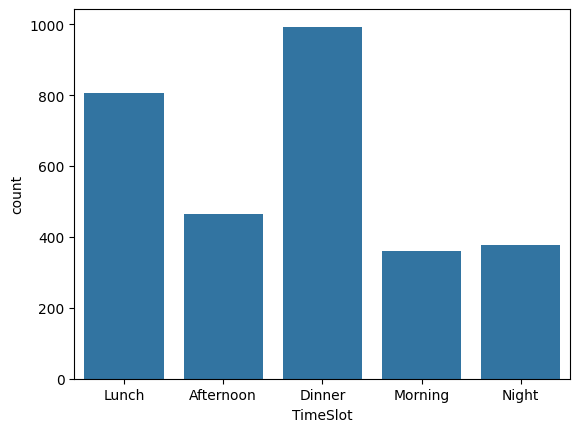

In [7]:
sns.countplot(data=data, x='TimeSlot')
plt.show()

답안3 = 'Dinner'

### 4. 거리(Distance)와 배달 소요시간(DeliveryTime)의 관계를 jointplot 으로 그리세요
- X축에 Distance, Y축에 DeliveryTime

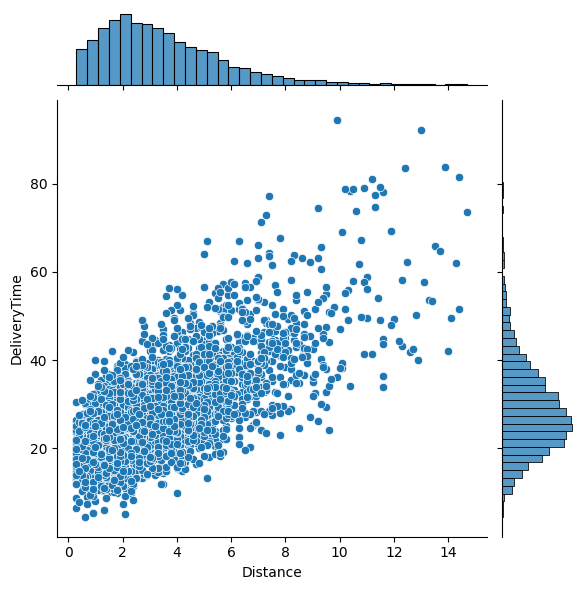

In [12]:
sns.jointplot(data=data, x='Distance', y='DeliveryTime')
plt.show()

## <데이터 전처리>
### 5. 평균 속도(AvgSpeed)가 150 이상인 행은 기록 오류입니다. 삭제하고 주문 번호(OrderID) 컬럼도 삭제하세요
- 결과는 `data_temp` 에 저장하세요. OrderID 삭제는 inplace=True 로 하세요.
- 남은 행 수를 `답안5` 에 저장하세요.

In [14]:
data_temp = data[data['AvgSpeed'] < 150].copy() # 남길 데이터를 복사 (150 이상은 오류라고 했으니 150미만을 남긴다.)
data_temp.drop('OrderID', axis=1, inplace=True) # 주문번호(OrderID) 컬럼(axis=1)을 drop 지운다. 단, inplace=True 로 한다.
답안5 = len(data_temp)
답안5

2970

### 6. 결측치 개수를 확인한 뒤 결측치가 있는 행을 모두 삭제해 `data_na` 에 저장하세요
- 남은 행 수를 `답안6` 에 저장하세요.

In [33]:
print(data_temp.isnull().sum()) #확인하세요 = 출력하세요 = print
data_na = data_temp.dropna()
답안6 = len(data_na)
답안6

DeliveryTime     0
Distance         0
AvgSpeed         0
PrepTime        89
CourierExp       0
Vehicle          0
TimeSlot         0
Weather         45
dtype: int64


2838

### 7. Vehicle, TimeSlot, Weather 를 원 핫 인코딩해 `data_preset` 에 저장하고 info 로 확인하세요
- 빈칸 `< blank7-1 >`, `< blank7-2 >` 에 들어갈 말을 `답안7_1`, `답안7_2` 에 저장하세요.

In [17]:
# 아래 코드의 빈칸을 채우고 실행하세요.
data_preset = pd.get_dummies(data=data_na, columns=['Vehicle', 'TimeSlot', 'Weather'])
data_preset.info()

답안7_1 = 'get_dummies'
답안7_2 = 'columns'

<class 'pandas.core.frame.DataFrame'>
Index: 2838 entries, 0 to 2999
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   DeliveryTime        2838 non-null   float64
 1   Distance            2838 non-null   float64
 2   AvgSpeed            2838 non-null   float64
 3   PrepTime            2838 non-null   float64
 4   CourierExp          2838 non-null   int64  
 5   Vehicle_Bike        2838 non-null   bool   
 6   Vehicle_Car         2838 non-null   bool   
 7   Vehicle_Scooter     2838 non-null   bool   
 8   TimeSlot_Afternoon  2838 non-null   bool   
 9   TimeSlot_Dinner     2838 non-null   bool   
 10  TimeSlot_Lunch      2838 non-null   bool   
 11  TimeSlot_Morning    2838 non-null   bool   
 12  TimeSlot_Night      2838 non-null   bool   
 13  Weather_Cloudy      2838 non-null   bool   
 14  Weather_Rainy       2838 non-null   bool   
 15  Weather_Snowy       2838 non-null   bool   
 16  Weather_Sun

### 8. DeliveryTime 을 레이블 y, 나머지를 피처 X 로 하고 학습용·검증용을 나누세요
- 변수: `X_train, X_valid, y_train, y_valid` · 비율 80:20 · 난수 시드 42
- 정답이 숫자(회귀)라서 비율 유지 옵션(stratify)은 쓰지 않습니다. 넣으면 에러가 납니다.

In [18]:
from sklearn.model_selection import train_test_split
X = data_preset.drop('DeliveryTime', axis=1)
y= data_preset['DeliveryTime']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

### 9. 스케일링 코드에 오류가 2곳 있습니다. 정정하고, 스케일링된 검증 데이터의 최댓값을 반올림해 `답안9` 에 저장하세요
- RobustScaler 를 쓰세요(중앙값과 IQR 로 재는 자, 쓰는 법은 StandardScaler 와 같습니다).
- 이 셀은 X_train, X_valid 를 덮어씁니다. 고친 뒤 다시 실행할 때는 8번 셀부터 다시 실행하세요.

In [19]:
# 아래의 코드를 정정하고 실행하세요.
from sklearn.preprocessing import RobustScaler
rs = RobustScaler()
X_train = rs.fit_transform(X_train)
X_valid = rs.transform(X_valid)
답안9 = print(round(np.max(X_valid)))
답안9

4


## <AI 모델링>
### 10. 배달 소요시간을 예측하는 DecisionTree(`dt`)와 RandomForest(`rf`) 회귀 모델을 만들고 학습하세요
- dt: 최대 깊이 5, min_samples_split 3, 난수 시드 42
- rf: n_estimators 100, 최대 깊이 10, min_samples_split 3, 난수 시드 42
- 회귀 모델은 이름 끝이 Regressor 입니다.

In [21]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

dt = DecisionTreeRegressor(max_depth=5, min_samples_split=3, random_state=42)
dt.fit(X_train, y_train)

rf = RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_split=3, random_state=42)
rf.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, min_samples_split=3, random_state=42)

### 11. RandomForest 의 변수 중요도 top 5 를 막대그래프로 그리려는데 에러가 납니다. 정정하고, 1위 피처 이름을 `답안11` 에 저장하세요

'Distance'

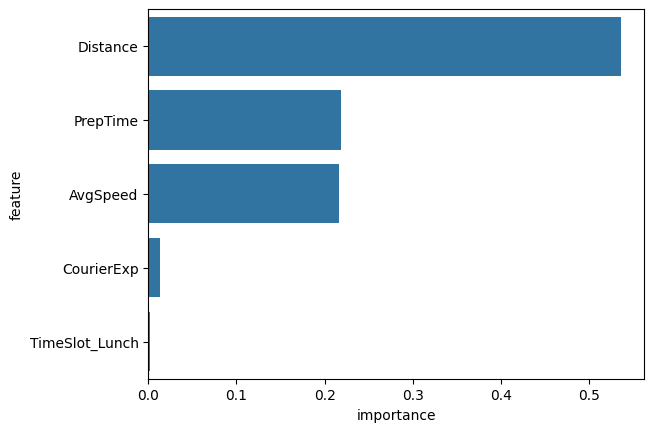

In [23]:
# 아래의 코드를 정정하고 실행하세요.
fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:5]
sns.barplot(x='importance', y='feature', data=fi)

답안11 = fi.iloc[0]['feature']
답안11

### 12. 두 모델의 검증 MAE(평균 절대 오차, 작을수록 좋다)를 구하려는데 오류가 3곳 있습니다. 정정하고, 더 우수한 모델 이름을 `답안12` 에 저장하세요 ('DecisionTree' 또는 'RandomForest')
- 예측 결과는 `y_pred_dt`, `y_pred_rf`, MAE 는 `dt_mae`, `rf_mae` 에 저장하고 두 값을 출력하세요.

In [28]:
# 아래의 코드를 정정하고 실행하세요.
y_pred_dt = dt.predict(X_valid) #검증용으로 채점
y_pred_rf = rf.predict(X_valid)
from sklearn.metrics import mean_absolute_error # 평균 절대 오차의 함수는 'mean_absolute_error' 까지가 풀네임
dt_mae = mean_absolute_error(y_valid, y_pred_dt)
rf_mae = mean_absolute_error(y_valid, y_pred_rf)
print(dt_mae) # 값을 출력
print(rf_mae)

답안12 = 'RandomForest' if rf_mae < dt_mae else 'DecisionTree' # MAE는 작을수록 좋다. <
답안12

3.8820466579593567
2.911837938333871


'RandomForest'

### 다음 문항을 풀기 전에 아래 코드를 실행하세요.

In [29]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
tf.keras.utils.set_random_seed(1)

### 13. 배달 소요시간을 예측하는 딥러닝 모델을 만들고 학습하세요
- 구조: Dense 64 (relu, input_dim) → Dropout 0.2 → Dense 32 (relu) → Dense 16 (relu) → Dense 1 (출력층)
- 숫자 하나를 내는 회귀라서 출력층은 1칸이고, LabelEncoder·to_categorical 은 쓰지 않습니다.
- compile: optimizer adam, metrics mse · EarlyStopping: val_loss 가 5번 나아지지 않으면 멈춤 · 학습: epochs 30, batch_size 128, 검증 데이터 지정 · 학습 정보는 `history`
- 빈칸에 들어갈 말을 `답안13_1`, `답안13_2` 에 저장하세요.
- 이 셀을 다시 실행하려면 위 준비 칸부터 다시 실행하세요(모델이 이어서 학습돼요).
- 결과 숫자는 컴퓨터마다 조금 다를 수 있어요.

In [34]:
# 아래 코드의 빈칸을 채우고 실행하세요.
model = Sequential([
    Dense(64, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='linear') #linear 숫자 하나를 그대로 내보낸다
])
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mse']) # mean_squared_error 줄여서 MSE
estop = EarlyStopping(monitor='val_loss', patience=5)
history = model.fit(X_train, y_train, batch_size=128, epochs=30, validation_data=(X_valid, y_valid), callbacks=[estop])

답안13_1 = 'linear'
답안13_2 = 'mean_squared_error'

Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 990.5193 - mse: 990.5193 - val_loss: 937.1387 - val_mse: 937.1387
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 960.7443 - mse: 960.7443 - val_loss: 905.6118 - val_mse: 905.6118
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 908.8475 - mse: 908.8475 - val_loss: 826.4006 - val_mse: 826.4006
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 783.7560 - mse: 783.7560 - val_loss: 647.7554 - val_mse: 647.7554
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 525.2618 - mse: 525.2618 - val_loss: 326.3864 - val_mse: 326.3864
Epoch 6/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 189.5970 - mse: 189.5970 - val_loss: 79.5759 - val_mse: 79.5759
Epoch 7/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 71.8348 - mse: 71.8348 - val_loss: 57.8699 - val_mse: 57.8699
Epoch 8/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 47.3941 - mse: 47.3941 - val_loss: 38.3807 - val_mse: 38.3807
Epoch 9/30
18/18 

### 14. 학습 MSE 와 검증 MSE 의 변화를 한 그래프에 그리세요
- 범례 'mse', 'val_mse' · 제목 'Model MSE' · x축 'Epoch' · y축 'MSE'
- 빈칸 `< blank14-1 >`, `< blank14-2 >` 에 들어갈 말을 `답안14_1`, `답안14_2` 에 저장하세요.

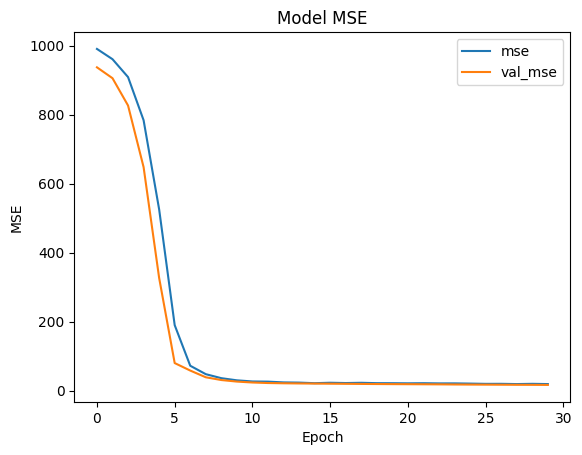

In [35]:
# 아래 코드의 빈칸을 채우고 실행하세요.
plt.plot(history.history['mse'])
plt.plot(history.history['val_mse'])
plt.title('Model MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend(['mse', 'val_mse'])
plt.show()

답안14_1 = 'history.history'
답안14_2 = 'legend'

---
### 모든 문항이 끝났습니다.
- 해설 노트북과 영상 12편으로 채점해 보세요. 분류와 다른 곳(stratify, Regressor, MAE, 출력층 1칸 linear, mean_squared_error)은 영상 12편 앞부분 표로 다시 정리하세요.